<a href="https://colab.research.google.com/github/Shatadru-Sarkar/Network_Intrusion_Detection/blob/main/Network_Intrusion_Detection_PBL_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Network Intrusion Detection (UNSW-NB15) – MCA PBL-2 Project
**Models:** Logistic Regression, Decision Tree, Random Forest  
**Task:** Binary classification – Normal (0) vs Malicious (1)

**Before running:** download `UNSW_NB15_training-set.csv` and `UNSW_NB15_testing-set.csv` (from the UNSW page or Kaggle: "UNSW-NB15"). These two files have column headers and ~257k rows in total. Run cells top to bottom.

## Step 1 – Load and understand the dataset

In [3]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, joblib, warnings
warnings.filterwarnings('ignore')
from google.colab import files

uploaded = files.upload()   # select BOTH csv files here
df = pd.concat([pd.read_csv(f) for f in uploaded if f.lower().endswith('.csv')], ignore_index=True)
print('Shape:', df.shape)
df.head()

Saving UNSW_NB15_testing-set.csv to UNSW_NB15_testing-set.csv
Saving UNSW_NB15_training-set.csv to UNSW_NB15_training-set.csv
Shape: (257673, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,...,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,...,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,...,1,3,0,0,0,1,3,0,Normal,0
3,4,0.000006,udp,-,INT,2,0,900,0,166666.6608,...,1,3,0,0,0,2,3,0,Normal,0
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.0025,...,1,3,0,0,0,2,3,0,Normal,0


In [4]:
print('Columns:', list(df.columns))
print()
df.info()

Columns: ['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257673 entries, 0 to 257672
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 257673 non-null  int64  
 1   dur                257673 non-null  float64
 2   proto              257673 non-null  object 
 3   service            257673 non-null  object 
 4   state              257673 non-null  object 
 5   spkts         

In [5]:
print('Binary target (label): 0 = Normal, 1 = Attack')
print(df['label'].value_counts())
print()
print('Multiclass target (attack_cat):')
print(df['attack_cat'].value_counts())

Binary target (label): 0 = Normal, 1 = Attack
label
1    164673
0     93000
Name: count, dtype: int64

Multiclass target (attack_cat):
attack_cat
Normal            93000
Generic           58871
Exploits          44525
Fuzzers           24246
DoS               16353
Reconnaissance    13987
Analysis           2677
Backdoor           2329
Shellcode          1511
Worms               174
Name: count, dtype: int64


## Step 2 – Exploratory Data Analysis (EDA)

In [6]:
# Missing values and duplicates
print('Total missing values:', df.isnull().sum().sum())
print('Duplicate rows (all columns):', df.duplicated().sum())
print('Duplicate rows (ignoring id):', df.drop(columns=['id'], errors='ignore').duplicated().sum())

num_cols = df.select_dtypes(include=np.number).columns.drop(['label'])
cat_cols = df.select_dtypes(exclude=np.number).columns
print('\nNumerical features:', len(num_cols))
print('Categorical features:', list(cat_cols))
df[num_cols].describe().T.head(15)

Total missing values: 0
Duplicate rows (all columns): 0
Duplicate rows (ignoring id): 94928

Numerical features: 40
Categorical features: ['proto', 'service', 'state', 'attack_cat']


,count,mean,std,min,25%,50%,75%,max
id,257673.0,7.281182e+04,4.892992e+04,1.0,32210.000000,64419.000000,1.109230e+05,1.753410e+05
dur,257673.0,1.246715e+00,5.974305e+00,0.0,0.000008,0.004285,6.857770e-01,5.999999e+01
spkts,257673.0,1.977714e+01,1.359472e+02,1.0,2.000000,4.000000,1.200000e+01,1.064600e+04
dpkts,257673.0,1.851470e+01,1.119860e+02,0.0,0.000000,2.000000,1.000000e+01,1.101800e+04
sbytes,257673.0,8.572952e+03,1.737739e+05,24.0,114.000000,528.000000,1.362000e+03,1.435577e+07
dbytes,257673.0,1.438729e+04,1.461993e+05,0.0,0.000000,178.000000,1.064000e+03,1.465753e+07
rate,257673.0,9.125391e+04,1.603446e+05,0.0,30.789277,2955.664893,1.250000e+05,1.000000e+06
sttl,257673.0,1.800009e+02,1.024883e+02,0.0,62.000000,254.000000,2.540000e+02,2.550000e+02
dttl,257673.0,8.475496e+01,1.127621e+02,0.0,0.000000,29.000000,2.520000e+02,2.540000e+02
sload,257673.0,7.060869e+07,1.857313e+08,0.0,12318.004880,743942.312500,8.000000e+07,5.988000e+09


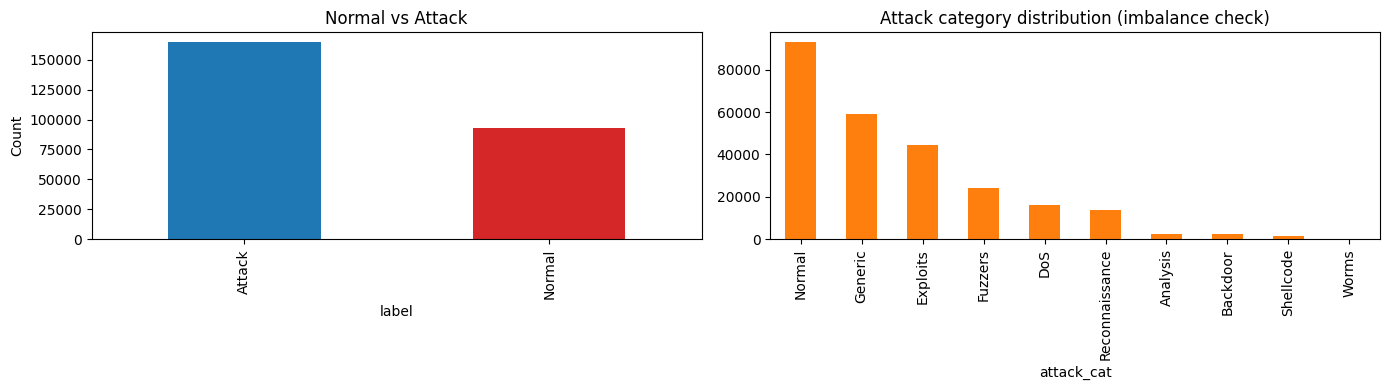

attack_cat
Normal            36.09
Generic           22.85
Exploits          17.28
Fuzzers            9.41
DoS                6.35
Reconnaissance     5.43
Analysis           1.04
Backdoor           0.90
Shellcode          0.59
Worms              0.07
Name: proportion, dtype: float64


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df['label'].map({0:'Normal', 1:'Attack'}).value_counts().plot(kind='bar', ax=ax[0], color=['tab:blue','tab:red'])
ax[0].set_title('Normal vs Attack'); ax[0].set_ylabel('Count')
df['attack_cat'].value_counts().plot(kind='bar', ax=ax[1], color='tab:orange')
ax[1].set_title('Attack category distribution (imbalance check)')
plt.tight_layout(); plt.show()

print((df['attack_cat'].value_counts(normalize=True)*100).round(2))

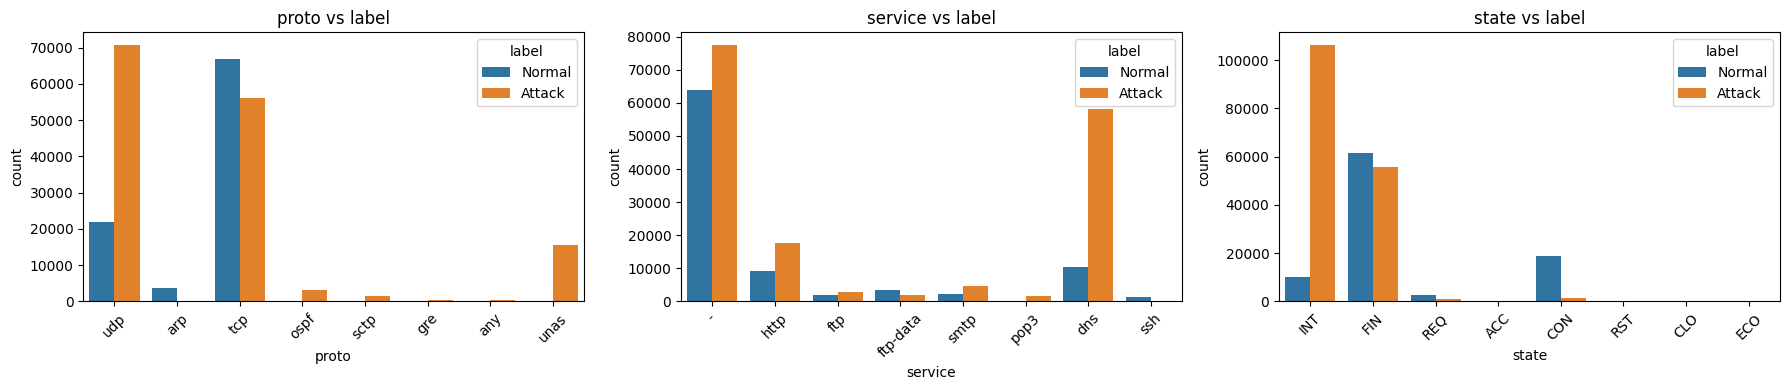

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, c in zip(ax, ['proto', 'service', 'state']):
    top = df[c].value_counts().head(8).index
    sns.countplot(data=df[df[c].isin(top)], x=c, hue=df['label'].map({0:'Normal',1:'Attack'}), ax=a)
    a.set_title(f'{c} vs label'); a.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

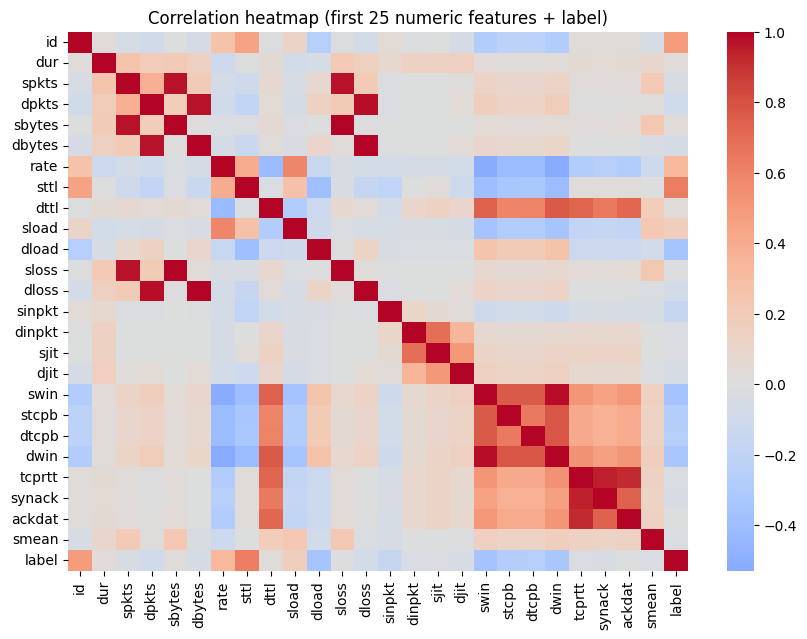

In [9]:
plt.figure(figsize=(10, 7))
corr = df[list(num_cols)[:25] + ['label']].corr()
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation heatmap (first 25 numeric features + label)')
plt.show()

## Step 3 – Prepare the data
- Drop `id` (just an identifier).  
- Drop `attack_cat` (it directly tells the attack type = **target leakage** for a binary model).  
- Drop duplicate rows.  
- Encode categoricals (One-Hot) and scale numerics inside a **Pipeline** so the exact same steps are reused for new data.

In [10]:
data = df.drop(columns=['id', 'attack_cat'], errors='ignore').drop_duplicates().reset_index(drop=True)
print('Shape after cleaning:', data.shape)

X = data.drop(columns=['label'])
y = data['label']

num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = X.select_dtypes(exclude=np.number).columns.tolist()
print('Numeric:', len(num_features), '| Categorical:', cat_features)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_features),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat_features)
])

Shape after cleaning: (154098, 43)
Numeric: 39 | Categorical: ['proto', 'service', 'state']


## Step 4 – Split the dataset
80% train / 20% test (stratified). The **test set is not touched** until Step 9.  
For Steps 5-6 I carve a small *validation* set out of the training data so the test set stays clean.

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape, '| (inner) Train:', X_tr.shape, '| Validation:', X_val.shape)

Train: (123278, 42) | Test: (30820, 42) | (inner) Train: (98622, 42) | Validation: (24656, 42)


## Step 5 – Train three classification models

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

def make_pipe(model):
    return Pipeline([('prep', preprocessor), ('model', model)])

models = {
    'Logistic Regression': make_pipe(LogisticRegression(max_iter=1000, random_state=42)),
    'Decision Tree':       make_pipe(DecisionTreeClassifier(random_state=42)),
    'Random Forest':       make_pipe(RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)),
}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    print('Trained:', name)

Trained: Logistic Regression
Trained: Decision Tree
Trained: Random Forest


## Step 6 – Evaluate and compare (on validation set)

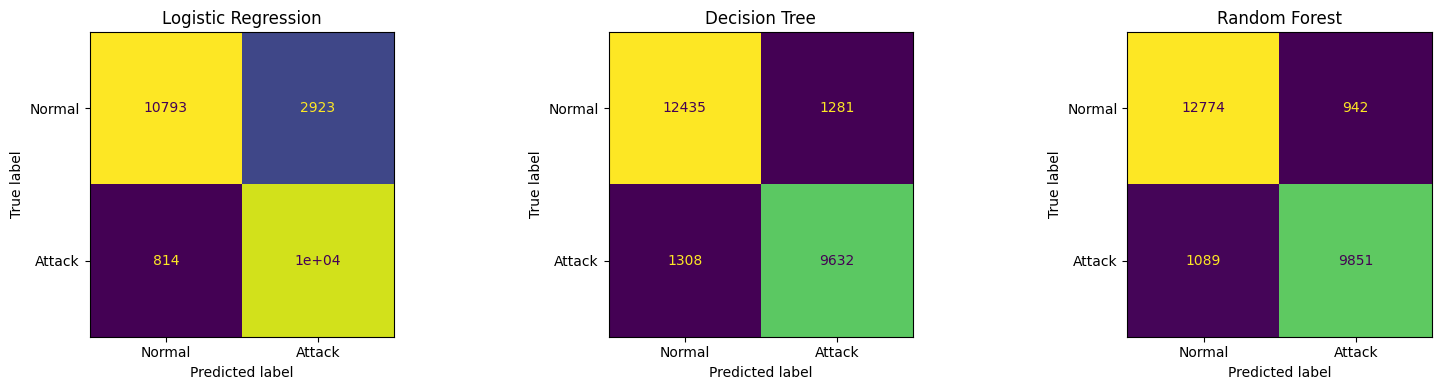

,Accuracy,Precision,Recall (Attack),F1-score,False Negatives,False Positives
Model,,,,,,
Logistic Regression,0.8484,0.7760,0.9256,0.8442,814,2923
Decision Tree,0.8950,0.8826,0.8804,0.8815,1308,1281
Random Forest,0.9176,0.9127,0.9005,0.9065,1089,942


 Logistic Regression
              precision    recall  f1-score   support

      Normal       0.93      0.79      0.85     13716
      Attack       0.78      0.93      0.84     10940

    accuracy                           0.85     24656
   macro avg       0.85      0.86      0.85     24656
weighted avg       0.86      0.85      0.85     24656

 Decision Tree
              precision    recall  f1-score   support

      Normal       0.90      0.91      0.91     13716
      Attack       0.88      0.88      0.88     10940

    accuracy                           0.89     24656
   macro avg       0.89      0.89      0.89     24656
weighted avg       0.89      0.89      0.89     24656

 Random Forest
              precision    recall  f1-score   support

      Normal       0.92      0.93      0.93     13716
      Attack       0.91      0.90      0.91     10940

    accuracy                           0.92     24656
   macro avg       0.92      0.92      0.92     24656
weighted avg       0.92

In [13]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

rows = []
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (name, m) in zip(ax, models.items()):
    pred = m.predict(X_val)
    cm = confusion_matrix(y_val, pred)
    rows.append({'Model': name,
                 'Accuracy': accuracy_score(y_val, pred),
                 'Precision': precision_score(y_val, pred),
                 'Recall (Attack)': recall_score(y_val, pred),
                 'F1-score': f1_score(y_val, pred),
                 'False Negatives': cm[1, 0],
                 'False Positives': cm[0, 1]})
    ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Attack']).plot(ax=a, colorbar=False)
    a.set_title(name)
plt.tight_layout(); plt.show()

comparison = pd.DataFrame(rows).set_index('Model').round(4)
display(comparison)

for name, m in models.items():
    print('=' * 60, '\n', name)
    print(classification_report(y_val, m.predict(X_val), target_names=['Normal', 'Attack']))

## Step 7 – 5-fold Cross-Validation
Dataset is large, so I use a stratified **30,000-row subset** of the training data to keep it fast.

In [14]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=30000, stratify=y_train, random_state=42)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
for name, m in models.items():
    scores = cross_val_score(m, X_sub, y_sub, cv=skf, scoring='f1', n_jobs=-1)
    print(f'{name}: {np.round(scores, 4)}  -> mean F1 = {scores.mean():.4f} (+/- {scores.std():.4f})')
    cv_rows.append({'Model': name, **{f'Fold {i+1}': s for i, s in enumerate(scores)}, 'Mean F1': scores.mean()})
display(pd.DataFrame(cv_rows).set_index('Model').round(4))

Logistic Regression: [0.8521 0.8428 0.8507 0.8414 0.849 ]  -> mean F1 = 0.8472 (+/- 0.0043)
Decision Tree: [0.867  0.8604 0.8648 0.8646 0.873 ]  -> mean F1 = 0.8660 (+/- 0.0041)
Random Forest: [0.8932 0.889  0.8933 0.8937 0.8949]  -> mean F1 = 0.8928 (+/- 0.0020)


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean F1
Model,,,,,,
Logistic Regression,0.8521,0.8428,0.8507,0.8414,0.8490,0.8472
Decision Tree,0.8670,0.8604,0.8648,0.8646,0.8730,0.8660
Random Forest,0.8932,0.8890,0.8933,0.8937,0.8949,0.8928


## Step 8 – Hyperparameter tuning with GridSearchCV

In [15]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    'Logistic Regression': {'model__C': [0.01, 0.1, 1, 10]},
    'Decision Tree':       {'model__max_depth': [5, 10, 20, None], 'model__min_samples_split': [2, 10]},
    'Random Forest':       {'model__n_estimators': [100, 200], 'model__max_depth': [10, 20, None]},
}
base = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree':       DecisionTreeClassifier(random_state=42),
    'Random Forest':       RandomForestClassifier(n_jobs=-1, random_state=42),
}

tuned, tune_rows = {}, []
for name in base:
    gs = GridSearchCV(make_pipe(base[name]), param_grids[name], cv=5, scoring='f1', n_jobs=-1)
    gs.fit(X_sub, y_sub)
    tuned[name] = gs
    print(f'{name}\n  Best params: {gs.best_params_}\n  Best CV F1 : {gs.best_score_:.4f}\n')
    tune_rows.append({'Model': name, 'Best Params': gs.best_params_, 'Best CV F1': round(gs.best_score_, 4)})
display(pd.DataFrame(tune_rows).set_index('Model'))

Logistic Regression
  Best params: {'model__C': 10}
  Best CV F1 : 0.8509

Decision Tree
  Best params: {'model__max_depth': 20, 'model__min_samples_split': 2}
  Best CV F1 : 0.8694

Random Forest
  Best params: {'model__max_depth': None, 'model__n_estimators': 200}
  Best CV F1 : 0.8956



,Best Params,Best CV F1
Model,,
Logistic Regression,{'model__C': 10},0.8509
Decision Tree,"{'model__max_depth': 20, 'model__min_samples_s...",0.8694
Random Forest,"{'model__max_depth': None, 'model__n_estimator...",0.8956


## Step 9 – Select the best model and evaluate ONCE on the test set
Best model = highest tuned CV F1-score. It is re-trained on the full training set, then tested one time.

Selected model: Random Forest

TEST SET RESULTS
              precision    recall  f1-score   support

      Normal       0.92      0.93      0.92     17145
      Attack       0.91      0.90      0.90     13675

    accuracy                           0.92     30820
   macro avg       0.91      0.91      0.91     30820
weighted avg       0.92      0.92      0.92     30820



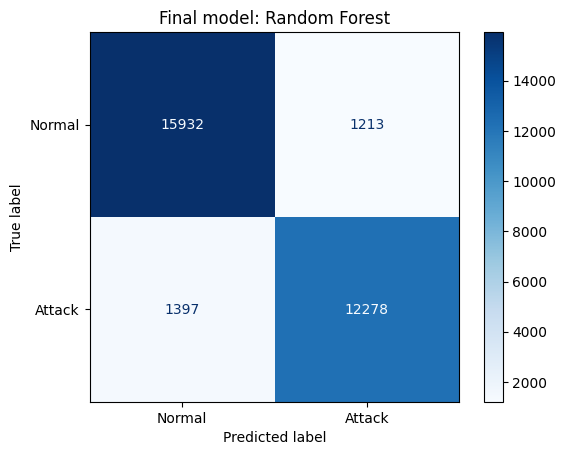

False Negatives (attacks missed): 1397
False Positives (normal flagged as attack): 1213


In [17]:
best_name = max(tuned, key=lambda k: tuned[k].best_score_)
print('Selected model:', best_name)

best_params = {k.replace('model__', ''): v for k, v in tuned[best_name].best_params_.items()}
final_model = make_pipe(base[best_name].set_params(**best_params))
final_model.fit(X_train, y_train)          # full training data

pred = final_model.predict(X_test)         # test set used only here
print('\nTEST SET RESULTS')
print(classification_report(y_test, pred, target_names=['Normal', 'Attack']))
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Attack']).plot(cmap='Blues')
plt.title(f'Final model: {best_name}'); plt.show()
print('False Negatives (attacks missed):', cm[1, 0])
print('False Positives (normal flagged as attack):', cm[0, 1])

## Step 10 & 11 – Save the pipeline and classify new data

In [18]:
joblib.dump({'model': final_model,
             'feature_cols': X.columns.tolist(),
             'defaults': {**X_train[num_features].median().to_dict(),
                          **X_train[cat_features].mode().iloc[0].to_dict()}},
            'intrusion_model.joblib')
files.download('intrusion_model.joblib')
print('Saved: intrusion_model.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved: intrusion_model.joblib


In [19]:
# Load the saved pipeline (works without retraining)
bundle = joblib.load('intrusion_model.joblib')

def predict_traffic(user_values: dict):
    """user_values: any subset of feature names; missing ones get typical (training) values."""
    row = {**bundle['defaults'], **user_values}
    df_row = pd.DataFrame([row])[bundle['feature_cols']]
    pred = bundle['model'].predict(df_row)[0]
    prob = bundle['model'].predict_proba(df_row)[0][1]
    label = 'Malicious Traffic' if pred == 1 else 'Normal Traffic'
    return label, prob

# Demo 1: a real record from the test set
sample = X_test.iloc[[0]].iloc[0].to_dict()
print('Actual label:', 'Malicious' if y_test.iloc[0] == 1 else 'Normal')
print('Prediction  :', predict_traffic(sample))

Actual label: Malicious
Prediction  : ('Malicious Traffic', np.float64(1.0))


In [21]:
# Demo 2: command-line style user input (press Enter to use the default value)
print('===== Network Intrusion Detection System =====')
fields = {'proto': str, 'service': str, 'state': str, 'dur': float,
          'spkts': float, 'dpkts': float, 'sbytes': float, 'dbytes': float}
user = {}
for f, t in fields.items():
    v = input(f'{f} [default {bundle["defaults"][f]}]: ').strip()
    if v:
        user[f] = t(v)

label, prob = predict_traffic(user)
print('\nPredicted class:', label)
print(f'Probability of attack: {prob:.2%}')

===== Network Intrusion Detection System =====
proto [default tcp]: tcp
service [default -]: http
state [default FIN]: FIN
dur [default 0.385166]: 
spkts [default 10.0]: 
dpkts [default 8.0]: 
sbytes [default 982.0]: 
dbytes [default 551.0]: 

Predicted class: Normal Traffic
Probability of attack: 48.50%


**Tip for the demo:** valid examples – `proto`: tcp / udp / icmp, `service`: http / dns / ftp / `-`, `state`: FIN / CON / INT.  
The model uses 40+ features; the ones you skip are filled with typical values, so predictions are best shown with a real test-set record (Demo 1).